# 06 · Sequence Features & Feature-Table Assembly (Milestone 2 · Person 4)

**Goal.**
1. Per observation: speed, heading, acceleration, time gaps and distances to neighbours (`features/sequence.py`).
2. Per candidate: distance rank among the competitors of the same observation.
3. Flag points after large gaps and choose the split threshold (proposal for Person 1 to confirm).
4. Assemble the final table from all four parts, save as parquet, and document it ([`docs/feature_table.md`](../docs/feature_table.md)).
5. Leakage checks: no duplicate (trip, obs, arc), no student-test trip in the training table, scaling fitted on training only.

The tables are built by `scripts/build_feature_table.py`; this notebook builds them too if they are missing, then analyses them.

## 1. Setup and build (if needed)

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import pyarrow.parquet as pq
from IPython.display import display

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from pathsnap.data.loader import discover_trips, load_trip
from pathsnap.utils.config import get_raw_data_dir
from pathsnap.road_network import load_split
from pathsnap.features import assembly as asm
from pathsnap.features.sequence import compute_observation_features

SEED = 42
cfg = yaml.safe_load((REPO_ROOT / "configs" / "features.yaml").read_text(encoding="utf-8"))
OUT = REPO_ROOT / cfg["output_dir"]; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TRAIN, TEST = OUT / "feature_table_train.parquet", OUT / "feature_table_student_test.parquet"
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

trips_index = discover_trips(get_raw_data_dir()); split = load_split()
if not (TRAIN.exists() and TEST.exists() and (OUT / "feature_table_summary.csv").exists()):
    t0 = time.time()
    s = asm.build_feature_tables(trips_index, split, OUT, partitions=cfg["partitions"], radius_m=cfg["radius_m"],
                                 max_candidates=cfg["max_candidates"], gap_policy=cfg["gap_policy"])
    s.to_csv(OUT / "feature_table_summary.csv", index=False)
    asm.save_scaler(asm.fit_scaler_from_parquet(TRAIN), OUT / "scaler_train.json")
    print(f"built in {time.time() - t0:.0f} s")
print("config:", {k: cfg[k] for k in ("radius_m", "max_candidates", "gap_policy")})

[INFO] 2026-11-18 12:59:23,447 - pathsnap.data.loader: Discovered 90 trips in C:\Users\Mateen\OneDrive\Desktop\ML-Hackathon-PT-082\data\raw


config: {'radius_m': 50.0, 'max_candidates': 30, 'gap_policy': {'flag_gap_s': 10.0, 'split_gap_s': 60.0, 'max_speed_mps': 70.0, 'min_move_m': 2.0}}


## 2. Gap threshold
Time gaps between consecutive GPS points over all 90 trips. The project data is ~1 Hz, so anything above a few seconds is a
gap. We count intervals and trips affected above candidate thresholds.

227,487 intervals; median 1.0 s; max 153,064 s


,threshold_s,intervals_over,pct_of_intervals,trips_affected
0,2,3075,1.352,53
1,5,1260,0.554,47
2,10,617,0.271,42
3,30,135,0.059,30
4,60,70,0.031,23
5,120,42,0.018,19
6,300,16,0.007,11


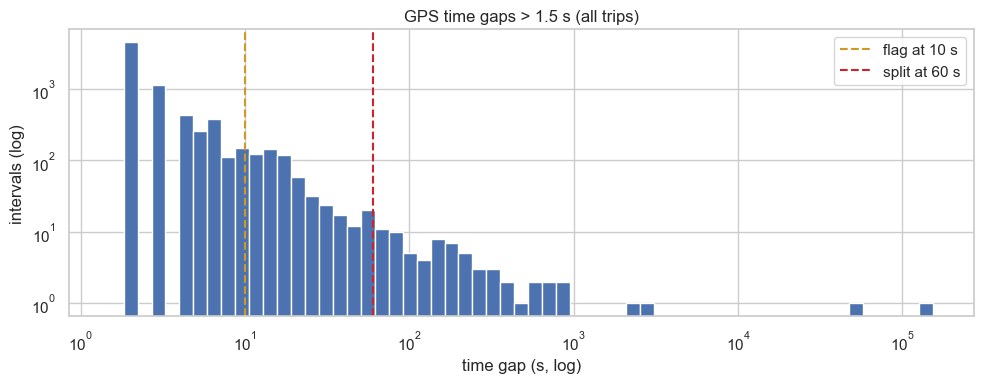

In [2]:
gaps, per_trip = [], []
for part in cfg["partitions"]:
    for tid in split[part]:
        tr = load_trip(tid, trips_index=trips_index, partition=part, project_utm=True)
        dt = np.diff(tr.track_utm.t.to_numpy())
        gaps.append(dt); per_trip.append((tid, part, dt))
dt = np.concatenate(gaps)
th = [2, 5, 10, 30, 60, 120, 300]
gap_table = pd.DataFrame({
    "threshold_s": th,
    "intervals_over": [int((dt > t).sum()) for t in th],
    "pct_of_intervals": [round(100 * (dt > t).mean(), 3) for t in th],
    "trips_affected": [sum((d > t).any() for _, _, d in per_trip) for t in th],
})
print(f"{len(dt):,} intervals; median {np.median(dt):.1f} s; max {dt.max():,.0f} s")
display(gap_table)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(dt[dt > 1.5], bins=np.logspace(np.log10(1.5), np.log10(dt.max()), 60), color="#4C72B0")
for t, c, lab in [(cfg["gap_policy"]["flag_gap_s"], "#d29922", "flag"), (cfg["gap_policy"]["split_gap_s"], "#cf222e", "split")]:
    ax.axvline(t, color=c, ls="--", label=f"{lab} at {t:.0f} s")
ax.set(xscale="log", yscale="log", xlabel="time gap (s, log)", ylabel="intervals (log)", title="GPS time gaps > 1.5 s (all trips)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "time_gaps.png", dpi=120); plt.show()
gap_table.to_csv(OUT / "gap_threshold_table.csv", index=False)

**Decision (proposal, to confirm with Person 1).** Flag at **10 s** (`after_gap`, `before_gap`) and split trips into
segments at **60 s** (`segment_id`). Gaps above 60 s are very rare but long enough (≈ 1 km at urban speed) that the path between
the two points is ambiguous, so the HMM should restart there. Both thresholds live in `configs/features.yaml`.

## 3. Table overview

In [3]:
summary = pd.read_csv(OUT / "feature_table_summary.csv", dtype={"trip_id": str})
meta = {p.name: pq.ParquetFile(p).metadata for p in (TRAIN, TEST)}
for name, m in meta.items():
    print(f"{name}: {m.num_rows:,} rows, {m.num_columns} columns, {m.num_row_groups} trips (row groups), "
          f"{(OUT / name).stat().st_size / 1e6:.1f} MB")
agg = summary.groupby("partition")[["rows", "observations", "obs_with_candidates", "positives", "obs_reference_in_candidates", "segments"]].sum()
agg["rows_per_obs"] = (agg.rows / agg.obs_with_candidates).round(2)
display(agg)
tr_s = summary[summary.partition == "train"].copy()
tr_s["coverage_pct"] = 100 * tr_s.obs_reference_in_candidates / tr_s.observations
print(f"Training observations whose reference arc is among the candidates: "
      f"{100 * tr_s.obs_reference_in_candidates.sum() / tr_s.observations.sum():.2f} %")
print("Lowest coverage trips:"); display(tr_s.nsmallest(5, "coverage_pct")[["trip_id", "observations", "obs_with_candidates", "coverage_pct"]].round(2))

feature_table_train.parquet: 1,772,015 rows, 47 columns, 80 trips (row groups), 78.1 MB
feature_table_student_test.parquet: 200,052 rows, 47 columns, 10 trips (row groups), 8.5 MB


,rows,observations,obs_with_candidates,positives,obs_reference_in_candidates,segments,rows_per_obs
partition,,,,,,,
student_test,200052,19160,19160,0.0,0.0,11,10.44
train,1772015,208417,190187,185103.0,185103.0,149,9.32


Training observations whose reference arc is among the candidates: 88.81 %
Lowest coverage trips:


,trip_id,observations,obs_with_candidates,coverage_pct
44,00000054,19313,2794,10.56
26,00000033,5844,5799,40.61
1,00000002,7243,6733,88.02
53,00000066,4325,4138,90.98
35,00000043,2322,2273,92.81


## 4. Feature distributions (training table, reproducible 5 % row sample)

In [4]:
pf = pq.ParquetFile(TRAIN)
rng = np.random.default_rng(SEED)
parts = []
for i in range(pf.num_row_groups):
    g = pf.read_row_group(i).to_pandas()
    parts.append(g[rng.random(len(g)) < 0.05])
sample = pd.concat(parts, ignore_index=True)
print(f"sample: {len(sample):,} rows")
obs_cols = ["speed_mps", "accel_mps2", "dt_prev_s", "dist_prev_m", "heading_change_deg"]
obs_sample = sample.drop_duplicates(["trip_id", "obs_idx"])
display(obs_sample[obs_cols].describe(percentiles=[.01, .5, .99]).T.round(2))
print("Flags (share of observations):", obs_sample[["after_gap", "before_gap", "is_segment_start", "implausible_speed"]].mean().round(5).to_dict())
display(sample[asm.FEATURE_COLUMNS].isna().mean().loc[lambda s: s > 0].mul(100).round(3).rename("missing_%").to_frame())

sample: 88,229 rows


,count,mean,std,min,1%,50%,99%,max
speed_mps,63881.0,13.13,8.58,0.06,2.03,10.96,42.23,109.77
accel_mps2,63767.0,0.01,7.92,-105.56,-19.83,-0.03,19.83,160.90
dt_prev_s,63820.0,1.12,1.24,1.00,1.00,1.00,4.00,57.00
dist_prev_m,63820.0,13.80,10.80,0.07,1.24,11.19,50.92,224.72
heading_change_deg,60421.0,69.57,55.09,0.00,0.80,53.98,177.52,180.00


Flags (share of observations): {'after_gap': 0.00326, 'before_gap': 0.00321, 'is_segment_start': 0.001, 'implausible_speed': 0.00061}


,missing_%
gps_heading_deg,0.090
bearing_diff_deg,0.090
bearing_diff_undirected_deg,0.090
dt_prev_s,0.103
dt_next_s,0.100
dist_prev_m,0.103
dist_next_m,0.100
speed_prev_mps,0.103
speed_next_mps,0.100
speed_mps,0.005


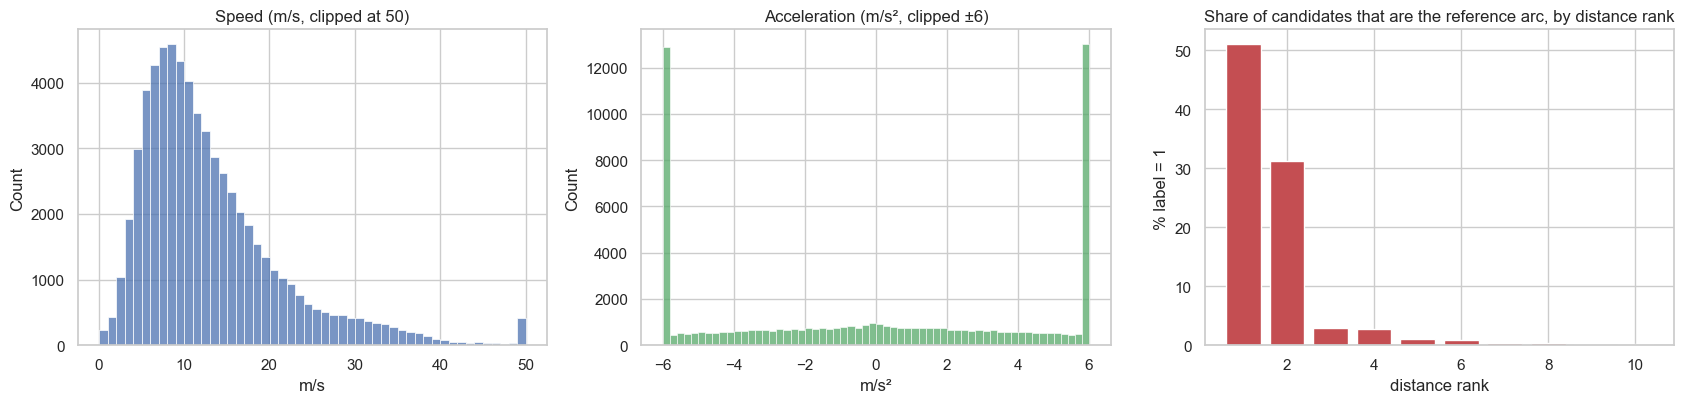

Positive rate by rank (%): {1: 51.01, 2: 31.31, 3: 2.88, 4: 2.84, 5: 1.11, 6: 0.81, 7: 0.39, 8: 0.4, 9: 0.27, 10: 0.22}


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(obs_sample.speed_mps.clip(upper=50), bins=50, ax=axes[0], color="#4C72B0")
axes[0].set(title="Speed (m/s, clipped at 50)", xlabel="m/s")
sns.histplot(obs_sample.accel_mps2.clip(-6, 6), bins=60, ax=axes[1], color="#55A868")
axes[1].set(title="Acceleration (m/s², clipped ±6)", xlabel="m/s²")
rank = sample.groupby("dist_rank").label.mean().head(10) * 100
axes[2].bar(rank.index, rank.values, color="#C44E52")
axes[2].set(title="Share of candidates that are the reference arc, by distance rank", xlabel="distance rank", ylabel="% label = 1")
plt.tight_layout(); plt.savefig(FIG / "sequence_features.png", dpi=120); plt.show()
print("Positive rate by rank (%):", rank.round(2).to_dict())

## 5. Required checks
* no duplicate (`trip_id`, `obs_idx`, `arc_id`) rows;
* no student-test trip in the training table (and partitions are pure);
* scaling statistics are fitted on training rows only (`fit_scaler` refuses other partitions; the saved scaler equals a
  refit on the training file).

The same checks run in `tests/test_sequence_assembly.py`.

In [6]:
keys_tr = pd.read_parquet(TRAIN, columns=["trip_id", "partition", "obs_idx", "arc_id"])
keys_te = pd.read_parquet(TEST, columns=["trip_id", "partition", "obs_idx", "arc_id", "label"])
checks = {
    "duplicate (trip, obs, arc) rows in train": int(keys_tr.duplicated(["trip_id", "obs_idx", "arc_id"]).sum()),
    "duplicate (trip, obs, arc) rows in student_test": int(keys_te.duplicated(["trip_id", "obs_idx", "arc_id"]).sum()),
    "student_test trips in training table": len(set(keys_tr.trip_id) & set(split["student_test"])),
    "non-train partition rows in training table": int((keys_tr.partition != "train").sum()),
    "training trips in table": keys_tr.trip_id.nunique(),
    "student_test trips in table": keys_te.trip_id.nunique(),
}
try:
    asm.fit_scaler(pd.concat([keys_tr.head(5), keys_te.head(5)]).assign(distance_m=1.0), ["distance_m"])
    checks["scaler refuses mixed partitions"] = False
except ValueError:
    checks["scaler refuses mixed partitions"] = True
saved = json.loads((OUT / "scaler_train.json").read_text(encoding="utf-8"))
refit = asm.fit_scaler_from_parquet(TRAIN)
checks["saved scaler == refit on train"] = all(np.isclose(saved["columns"][c]["mean"], refit[c]["mean"]) for c in refit)
checks["scaled columns"] = len(saved["columns"])
display(pd.Series(checks, name="result").to_frame())
assert checks["duplicate (trip, obs, arc) rows in train"] == 0 and checks["student_test trips in table"] == 10
assert checks["student_test trips in training table"] == 0 and checks["scaler refuses mixed partitions"]
del keys_tr, keys_te

,result
"duplicate (trip, obs, arc) rows in train",0
"duplicate (trip, obs, arc) rows in student_test",0
student_test trips in training table,0
non-train partition rows in training table,0
training trips in table,80
student_test trips in table,10
scaler refuses mixed partitions,True
saved scaler == refit on train,True
scaled columns,29


## 6. Findings

In [7]:
a = agg
facts = [
    f"Training table: {int(a.loc['train', 'rows']):,} rows from {int(a.loc['train', 'obs_with_candidates']):,} observations "
    f"({a.loc['train', 'rows_per_obs']} candidates per observation); student_test: {int(a.loc['student_test', 'rows']):,} rows.",
    f"{len(asm.COLUMN_ORDER)} columns: 4 keys, 2 label columns, {len(asm.FEATURE_COLUMNS)} features "
    f"({len(asm.SCALE_COLUMNS)} continuous columns in the train-only scaler).",
    f"Reference arc among the candidates for {100 * tr_s.obs_reference_in_candidates.sum() / tr_s.observations.sum():.2f} % of "
    f"training observations (radius {cfg['radius_m']:.0f} m, cap {cfg['max_candidates']}).",
    f"The nearest candidate (rank 1) is the reference arc {rank.iloc[0]:.1f} % of the time; rank 2: {rank.iloc[1]:.1f} %.",
    f"Gaps: {gap_table.set_index('threshold_s').loc[10, 'intervals_over']} intervals > 10 s "
    f"({gap_table.set_index('threshold_s').loc[10, 'trips_affected']} trips) and "
    f"{gap_table.set_index('threshold_s').loc[60, 'intervals_over']} > 60 s "
    f"({gap_table.set_index('threshold_s').loc[60, 'trips_affected']} trips) -> flag at 10 s, split at 60 s.",
    "All required checks passed: no duplicate keys, no student_test trip in the training table, scaler fitted on train only.",
]
for i, f in enumerate(facts, 1):
    print(f"{i}. {f}")

1. Training table: 1,772,015 rows from 190,187 observations (9.32 candidates per observation); student_test: 200,052 rows.
2. 47 columns: 4 keys, 2 label columns, 41 features (29 continuous columns in the train-only scaler).
3. Reference arc among the candidates for 88.81 % of training observations (radius 50 m, cap 30).
4. The nearest candidate (rank 1) is the reference arc 51.0 % of the time; rank 2: 31.3 %.
5. Gaps: 617 intervals > 10 s (42 trips) and 70 > 60 s (23 trips) -> flag at 10 s, split at 60 s.
6. All required checks passed: no duplicate keys, no student_test trip in the training table, scaler fitted on train only.


### Open points for the team
* **Gap thresholds** (10 s flag / 60 s split) are a proposal; Person 1 to confirm.
* **student_test labels** are null because Person 2's alignment only accepts training trips. Evaluating on student_test
  needs that guard extended (labels are used for evaluation only, not fitting).
* **Trip 00000054** has very low candidate coverage (GPS offset from the map, see notebooks 04/05); consider excluding it.
* `*.parquet` is git-ignored: regenerate the tables with `python scripts/build_feature_table.py` (~2–3 min).